# LitGPT vs HF Transformers: Q/K/V Extraction Benchmark (Llama-3.2-1B)

This notebook runs on Colab (T4 GPU) and compares **HF Transformers** vs **LitGPT** for:
- first 100 samples from ShareGPT
- inference with `meta-llama/Llama-3.2-1B-Instruct`
- extraction of Q, K, V at the same attention layer index
- saving Q/K/V tensors to one file per framework
- timing and throughput comparison

Notes:
- You need a Hugging Face token with access to Llama 3.2 weights.
- This benchmark measures prompt forward pass + Q/K/V extraction (not autoregressive generation loops).

In [1]:
!pip install -q litgpt transformers datasets torch huggingface_hub sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.6/201.6 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 263.3/263.3 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 562.6/562.6 kB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.5/228.5 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 760.5/760.5 kB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 63.6 MB/s eta 0:00:00


In [2]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import login
from transformers import AutoModelForCausalLM, AutoTokenizer

# ====== User-configurable ======
MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"
NUM_SAMPLES = 100
LAYER_IDX = 5              # keep identical across both frameworks
MAX_INPUT_TOKENS = 128     # reduce if you hit memory issues
OUT_DIR = Path("qkv_outputs")
STORE_DTYPE = torch.float16
# ===============================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

OUT_DIR.mkdir(parents=True, exist_ok=True)
torch.set_grad_enabled(False)

HF_TOKEN = os.getenv("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
        if HF_TOKEN:
            print("HF token loaded from Colab Secrets.")
    except Exception:
        pass

if not HF_TOKEN:
    from getpass import getpass
    HF_TOKEN = getpass("Enter your Hugging Face token (hf_...): ").strip()

if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("HF login: OK")
else:
    raise ValueError("HF token is required for this model. Set Colab secret HF_TOKEN or enter it when prompted.")

Device: cuda
GPU: Tesla T4
Enter your Hugging Face token (hf_...): ··········
HF login: OK


In [3]:
# alpaca = load_dataset("tatsu-lab/alpaca", split=f"train[:{NUM_SAMPLES}]")

# def build_alpaca_prompt(row):
#     instruction = row.get("instruction", "").strip()
#     inp = row.get("input", "").strip()
#     if inp:
#         return f"Instruction:\n{instruction}\n\nInput:\n{inp}\n\nResponse:\n"
#     return f"Instruction:\n{instruction}\n\nResponse:\n"

# prompts = [build_alpaca_prompt(r) for r in alpaca]
# print("Loaded prompts:", len(prompts))
# print(prompts[0][:300])

In [8]:
from datasets import load_dataset

NUM_SAMPLES = 100  # adjust as needed

# Load ShareGPT instruct dataset (streaming version is safer for large datasets)
sharegpt = load_dataset("CaterinaLac/sharegpt-deduplicated", split=f"train[:{NUM_SAMPLES}]")

def build_sharegpt_prompt(row):
    """
    Builds a prompt in the same format as ShareGPT:
    Instruction: <instruction>
    Input: <input>      (optional)
    Response: <response>
    """
    # ShareGPT dataset has fields like "input" and "output"
    instruction = row.get("input", "").strip()   # treat "input" as instruction
    inp = ""  # ShareGPT usually doesn't have separate 'input' field
    response = row.get("output", "").strip()

    if inp:
        return f"Instruction:\n{instruction}\n\nInput:\n{inp}\n\nResponse:\n{response}"
    else:
        return f"Instruction:\n{instruction}\n\nResponse:\n{response}"

# Build prompts
prompts = [build_sharegpt_prompt(r) for r in sharegpt]

print("Loaded prompts:", len(prompts))
print(prompts[0][:300])


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.jsonl:   0%|          | 0.00/71.2M [00:00<?, ?B/s]

validation.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/5040 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Loaded prompts: 100
Instruction:
Human: I want to build a DIY pool heater controller for my Mastertemp 250 pool heater. I have an ARDUINO UNO WiFi REV2 to use for this project. Can you help me to know what else I'll need physically to do this project? I can handle the coding myself.
Assistant: Sure, I'd be happy to hel


In [ ]:
def summarize_metrics(name, latencies_s, lengths, peak_mem_bytes):
    lat = np.array(latencies_s, dtype=np.float64)
    total_time = float(lat.sum())
    total_tokens = int(np.sum(lengths))
    return {
        "framework": name,
        "samples": int(len(latencies_s)),
        "total_time_s": total_time,
        "mean_latency_ms": float(lat.mean() * 1000.0),
        "p50_latency_ms": float(np.percentile(lat, 50) * 1000.0),
        "p95_latency_ms": float(np.percentile(lat, 95) * 1000.0),
        "prompt_tokens_total": total_tokens,
        "prompt_tokens_per_s": float(total_tokens / total_time) if total_time > 0 else float("nan"),
        "gpu_peak_mem_gb": float(peak_mem_bytes / 1e9) if peak_mem_bytes is not None else float("nan"),
    }

def split_litgpt_qkv(qkv, attn_module):
    # Reconstruct q,k,v exactly as LitGPT does before RoPE is applied
    cfg = attn_module.config
    B, T, _ = qkv.shape
    n_head = int(cfg.n_head)
    n_query_groups = int(getattr(cfg, "n_query_groups", n_head))
    head_size = int(cfg.head_size)

    q_per_kv = n_head // n_query_groups
    total_qkv = q_per_kv + 2

    qkv = qkv.view(B, T, n_query_groups, total_qkv, head_size)
    qkv = qkv.permute(0, 2, 3, 1, 4)
    q, k, v = qkv.split((q_per_kv, 1, 1), dim=2)

    if n_query_groups != n_head:
        q = q.expand(B, n_query_groups, q_per_kv, T, head_size)
        k = k.expand(B, n_query_groups, q_per_kv, T, head_size)
        v = v.expand(B, n_query_groups, q_per_kv, T, head_size)

    q = q.reshape(B, -1, T, head_size).permute(0, 2, 1, 3).reshape(B, T, -1)
    k = k.reshape(B, -1, T, head_size).permute(0, 2, 1, 3).reshape(B, T, -1)
    v = v.reshape(B, -1, T, head_size).permute(0, 2, 1, 3).reshape(B, T, -1)
    return q, k, v

In [ ]:
# def run_hf(prompts):
#     dtype = torch.bfloat16 if DEVICE == "cuda" else torch.float32

#     tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN, use_fast=True)
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     model = AutoModelForCausalLM.from_pretrained(
#         MODEL_ID,
#         token=HF_TOKEN,
#         torch_dtype=dtype,
#         device_map="auto" if DEVICE == "cuda" else None,
#     )
#     if DEVICE != "cuda":
#         model.to(DEVICE)
#     model.eval()

#     if not (0 <= LAYER_IDX < len(model.model.layers)):
#         raise ValueError(f"LAYER_IDX={LAYER_IDX} out of range for HF model ({len(model.model.layers)} layers)")

#     attn = model.model.layers[LAYER_IDX].self_attn
#     num_heads = int(model.config.num_attention_heads)
#     num_kv_heads = int(getattr(model.config, "num_key_value_heads", num_heads))
#     head_dim = int(getattr(model.config, "head_dim", model.config.hidden_size // num_heads))
#     hidden_size = num_heads * head_dim

#     def expand_kv_to_q_heads(x):
#         # HF returns grouped K/V for GQA models; expand to query-head width for parity with LitGPT split
#         b, t, _ = x.shape
#         x = x.view(b, t, num_kv_heads, head_dim)
#         if num_kv_heads != num_heads:
#             repeat = num_heads // num_kv_heads
#             x = x.repeat_interleave(repeat, dim=2)
#         return x.reshape(b, t, hidden_size)

#     cache = {}
#     def mk_hook(name):
#         def _hook(_module, _inp, out):
#             cache[name] = out.detach()
#         return _hook

#     handles = [
#         attn.q_proj.register_forward_hook(mk_hook("q")),
#         attn.k_proj.register_forward_hook(mk_hook("k")),
#         attn.v_proj.register_forward_hook(mk_hook("v")),
#     ]

#     q_store = torch.zeros((NUM_SAMPLES, MAX_INPUT_TOKENS, hidden_size), dtype=STORE_DTYPE)
#     k_store = torch.zeros_like(q_store)
#     v_store = torch.zeros_like(q_store)
#     lengths = []
#     latencies = []

#     model_device = next(model.parameters()).device

#     warm = tokenizer(prompts[0], return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model_device)
#     with torch.inference_mode():
#         _ = model(**warm, use_cache=False)

#     if DEVICE == "cuda":
#         torch.cuda.synchronize()
#         torch.cuda.reset_peak_memory_stats()

#     for i, p in enumerate(prompts):
#         cache.clear()
#         inputs = tokenizer(p, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model_device)

#         if DEVICE == "cuda":
#             torch.cuda.synchronize()
#         t0 = time.perf_counter()
#         with torch.inference_mode():
#             _ = model(**inputs, use_cache=False)
#         if DEVICE == "cuda":
#             torch.cuda.synchronize()
#         latencies.append(time.perf_counter() - t0)

#         q = cache["q"][0].to(STORE_DTYPE).cpu()
#         k = expand_kv_to_q_heads(cache["k"])[0].to(STORE_DTYPE).cpu()
#         v = expand_kv_to_q_heads(cache["v"])[0].to(STORE_DTYPE).cpu()

#         if q.shape[1] != hidden_size or k.shape[1] != hidden_size or v.shape[1] != hidden_size:
#             raise ValueError(
#                 f"Unexpected QKV widths: q={q.shape}, k={k.shape}, v={v.shape}, expected hidden_size={hidden_size}"
#             )

#         L = min(q.shape[0], k.shape[0], v.shape[0], MAX_INPUT_TOKENS)
#         lengths.append(int(L))
#         q_store[i, :L] = q[:L]
#         k_store[i, :L] = k[:L]
#         v_store[i, :L] = v[:L]

#     for h in handles:
#         h.remove()

#     peak_mem = torch.cuda.max_memory_allocated() if DEVICE == "cuda" else None
#     out_file = OUT_DIR / f"hf_qkv_layer{LAYER_IDX}.pt"
#     torch.save({
#         "framework": "hf_transformers",
#         "model_id": MODEL_ID,
#         "layer_idx": LAYER_IDX,
#         "max_input_tokens": MAX_INPUT_TOKENS,
#         "kv_expanded_to_num_heads": True,
#         "lengths": torch.tensor(lengths, dtype=torch.int32),
#         "q": q_store,
#         "k": k_store,
#         "v": v_store,
#     }, out_file)

#     metrics = summarize_metrics("hf_transformers", latencies, lengths, peak_mem)
#     metrics["qkv_file"] = str(out_file)
#     return metrics


In [6]:
def run_hf(prompts, model, tokenizer, layer_idx):
    # Use the passed layer_idx
    if not (0 <= layer_idx < len(model.model.layers)):
        raise ValueError(f"layer_idx={layer_idx} out of range for HF model ({len(model.model.layers)} layers)")

    attn = model.model.layers[layer_idx].self_attn
    num_heads = int(model.config.num_attention_heads)
    num_kv_heads = int(getattr(model.config, "num_key_value_heads", num_heads))
    head_dim = int(getattr(model.config, "head_dim", model.config.hidden_size // num_heads))
    hidden_size = num_heads * head_dim

    def expand_kv_to_q_heads(x):
        b, t, _ = x.shape
        x = x.view(b, t, num_kv_heads, head_dim)
        if num_kv_heads != num_heads:
            repeat = num_heads // num_kv_heads
            x = x.repeat_interleave(repeat, dim=2)
        return x.reshape(b, t, hidden_size)

    cache = {}
    def mk_hook(name):
        def _hook(_module, _inp, out):
            cache[name] = out.detach()
        return _hook

    handles = [
        attn.q_proj.register_forward_hook(mk_hook("q")),
        attn.k_proj.register_forward_hook(mk_hook("k")),
        attn.v_proj.register_forward_hook(mk_hook("v")),
    ]

    q_store = torch.zeros((NUM_SAMPLES, MAX_INPUT_TOKENS, hidden_size), dtype=STORE_DTYPE)
    k_store = torch.zeros_like(q_store)
    v_store = torch.zeros_like(q_store)
    lengths = []
    latencies = []

    model_device = next(model.parameters()).device

    # Perform a single warmup for this layer
    warm = tokenizer(prompts[0], return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model_device)
    with torch.inference_mode():
        _ = model(**warm, use_cache=False)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    for i, p in enumerate(prompts):
        cache.clear()
        inputs = tokenizer(p, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model_device)

        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            _ = model(**inputs, use_cache=False)
        if DEVICE == "cuda": torch.cuda.synchronize()
        latencies.append(time.perf_counter() - t0)

        q = cache["q"][0].to(STORE_DTYPE).cpu()
        k = expand_kv_to_q_heads(cache["k"])[0].to(STORE_DTYPE).cpu()
        v = expand_kv_to_q_heads(cache["v"])[0].to(STORE_DTYPE).cpu()

        L = min(q.shape[0], k.shape[0], v.shape[0], MAX_INPUT_TOKENS)
        lengths.append(int(L))
        q_store[i, :L] = q[:L]
        k_store[i, :L] = k[:L]
        v_store[i, :L] = v[:L]

    for h in handles:
        h.remove()

    peak_mem = torch.cuda.max_memory_allocated() if DEVICE == "cuda" else None
    out_file = OUT_DIR / f"hf_qkv_layer{layer_idx}.pt"
    torch.save({
        "framework": "hf_transformers",
        "model_id": MODEL_ID,
        "layer_idx": layer_idx,
        "q": q_store, "k": k_store, "v": v_store,
    }, out_file)

    metrics = summarize_metrics("hf_transformers", latencies, lengths, peak_mem)
    metrics["qkv_file"] = str(out_file)
    return metrics

In [ ]:
from litgpt import LLM
import huggingface_hub.constants
import inspect
if not hasattr(huggingface_hub.constants, "HF_HUB_ENABLE_HF_TRANSFER"):
    setattr(huggingface_hub.constants, "HF_HUB_ENABLE_HF_TRANSFER", False)
def run_litgpt(prompts):

    precision = "bf16-true" if DEVICE == "cuda" else "32-true"

    sig = inspect.signature(LLM.load)
    load_kwargs = {}
    if "model" in sig.parameters:
        load_kwargs["model"] = MODEL_ID
    if "distribute" in sig.parameters:
        load_kwargs["distribute"] = "auto"
    if "access_token" in sig.parameters and HF_TOKEN:
        load_kwargs["access_token"] = HF_TOKEN
    if "token" in sig.parameters and HF_TOKEN:
        load_kwargs["token"] = HF_TOKEN

    try:
        llm = LLM.load(**load_kwargs)
    except TypeError:
        # Fallback for older/newer LitGPT signatures
        llm = LLM.load(MODEL_ID)

    if getattr(llm, "model", None) is None:
        if hasattr(llm, "distribute"):
            llm.distribute(
                accelerator="cuda" if DEVICE == "cuda" else "cpu",
                devices=1,
                precision=precision,
            )
        else:
            raise RuntimeError("LitGPT returned model=None and has no distribute() method.")

    if getattr(llm, "model", None) is None:
        raise RuntimeError("LitGPT model is still None after distribute().")

    llm.model.eval()

    if hasattr(llm.model, "transformer") and hasattr(llm.model.transformer, "h"):
        blocks = llm.model.transformer.h
    elif hasattr(llm.model, "layers"):
        blocks = llm.model.layers
    else:
        raise RuntimeError("Unable to locate transformer blocks in LitGPT model")

    if not (0 <= LAYER_IDX < len(blocks)):
        raise ValueError(f"LAYER_IDX={LAYER_IDX} out of range for LitGPT model ({len(blocks)} layers)")

    block = blocks[LAYER_IDX]
    attn = getattr(block, "attn", None) or getattr(block, "self_attn", None)
    if attn is None:
        raise RuntimeError("Unable to locate attention module in LitGPT block")

    qkv_proj = getattr(attn, "attn", None) or getattr(attn, "qkv", None)
    if qkv_proj is None:
        raise RuntimeError("Unable to locate LitGPT qkv projection module for hook")

    cache = {}

    def qkv_hook(_module, _inp, out):
        if isinstance(out, (tuple, list)):
            out = out[0]
        cache["qkv"] = out.detach()

    handle = qkv_proj.register_forward_hook(qkv_hook)

    cfg = llm.model.config
    n_embd = getattr(cfg, "n_embd", None)
    if n_embd is None:
        n_embd = getattr(cfg, "hidden_size", None)
    if n_embd is None:
        n_embd = int(cfg.n_head) * int(cfg.head_size)
    hidden_size = int(n_embd)

    q_store = torch.zeros((NUM_SAMPLES, MAX_INPUT_TOKENS, hidden_size), dtype=STORE_DTYPE)
    k_store = torch.zeros_like(q_store)
    v_store = torch.zeros_like(q_store)
    lengths = []
    latencies = []

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN, use_fast=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model_device = next(llm.model.parameters()).device

    def encode_prompt(text):
        ids = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS)["input_ids"][0]
        return ids.to(model_device)

    warm_ids = encode_prompt(prompts[0]).unsqueeze(0)
    with torch.inference_mode():
        _ = llm.model(warm_ids)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    class _Wrap:
        pass
    attn_for_split = attn
    if not hasattr(attn_for_split, "config"):
        w = _Wrap()
        w.config = cfg
        attn_for_split = w

    for i, p in enumerate(prompts):
        cache.clear()
        ids = encode_prompt(p)
        x = ids.unsqueeze(0)

        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            _ = llm.model(x)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        latencies.append(time.perf_counter() - t0)

        if "qkv" not in cache:
            raise RuntimeError("LitGPT hook did not capture qkv output")

        qkv = cache["qkv"]
        q, k, v = split_litgpt_qkv(qkv, attn_for_split)
        q = q[0].to(STORE_DTYPE).cpu()
        k = k[0].to(STORE_DTYPE).cpu()
        v = v[0].to(STORE_DTYPE).cpu()

        if q.shape[1] != hidden_size or k.shape[1] != hidden_size or v.shape[1] != hidden_size:
            raise ValueError(
                f"Unexpected LitGPT QKV widths: q={q.shape}, k={k.shape}, v={v.shape}, expected hidden_size={hidden_size}"
            )

        L = min(q.shape[0], k.shape[0], v.shape[0], MAX_INPUT_TOKENS)
        lengths.append(int(L))
        q_store[i, :L] = q[:L]
        k_store[i, :L] = k[:L]
        v_store[i, :L] = v[:L]

    handle.remove()

    peak_mem = torch.cuda.max_memory_allocated() if DEVICE == "cuda" else None
    out_file = OUT_DIR / f"litgpt_qkv_layer{LAYER_IDX}.pt"
    torch.save({
        "framework": "litgpt",
        "model_id": MODEL_ID,
        "layer_idx": LAYER_IDX,
        "max_input_tokens": MAX_INPUT_TOKENS,
        "lengths": torch.tensor(lengths, dtype=torch.int32),
        "q": q_store,
        "k": k_store,
        "v": v_store,
    }, out_file)

    metrics = summarize_metrics("litgpt", latencies, lengths, peak_mem)
    metrics["qkv_file"] = str(out_file)
    return metrics


In [ ]:
# !pip uninstall -y transformers
# !pip install transformers>=4.43.0

In [ ]:
import transformers
print(transformers.__version__)
# Should be >= 4.43.0

4.57.6


In [ ]:
import pandas as pd

# Compute average prompt length (in characters)
avg_prompt_len = sum(len(p) for p in prompts) / len(prompts)

# Or, if you want it in tokens, you could do:
# avg_prompt_len = sum(len(tokenizer(p)["input_ids"]) for p in prompts) / len(prompts)

hf_metrics = run_hf(prompts)
litgpt_metrics = run_litgpt(prompts)

comparison = pd.DataFrame([hf_metrics, litgpt_metrics])

# Add average prompt length column
comparison["avg_prompt_len"] = avg_prompt_len

# Reorder columns, putting avg_prompt_len at the end
comparison = comparison[[
    "framework",
    "samples",
    "total_time_s",
    "mean_latency_ms",
    "p50_latency_ms",
    "p95_latency_ms",
    "prompt_tokens_total",
    "prompt_tokens_per_s",
    "gpu_peak_mem_gb",
    "qkv_file",
    "avg_prompt_len",   # new column
]]

comparison


,framework,samples,total_time_s,mean_latency_ms,p50_latency_ms,p95_latency_ms,prompt_tokens_total,prompt_tokens_per_s,gpu_peak_mem_gb,qkv_file,avg_prompt_len
0,hf_transformers,100,15.467832,154.678316,156.189293,162.539369,12688,820.283045,2.547131,qkv_outputs/hf_qkv_layer5.pt,8810.18
1,litgpt,100,15.210584,152.105838,154.460306,157.867082,12688,834.156015,3.204782,qkv_outputs/litgpt_qkv_layer5.pt,8810.18


In [ ]:
faster = comparison.sort_values("total_time_s").iloc[0]
print("Faster (this run):", faster["framework"])
print("\nSaved files:")
for p in comparison["qkv_file"].tolist():
    print(" -", p)

print("\nTo load a saved tensor file later:")
print("obj = torch.load('<path>.pt', map_location='cpu')")
print("obj.keys() ->", ["framework", "model_id", "layer_idx", "max_input_tokens", "lengths", "q", "k", "v"])

Faster (this run): litgpt

Saved files:
 - qkv_outputs/hf_qkv_layer5.pt
 - qkv_outputs/litgpt_qkv_layer5.pt

To load a saved tensor file later:
obj = torch.load('<path>.pt', map_location='cpu')
obj.keys() -> ['framework', 'model_id', 'layer_idx', 'max_input_tokens', 'lengths', 'q', 'k', 'v']


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token



def avg_truncated_char_length(prompts, tokenizer, max_tokens):
    total_chars = 0

    for p in prompts:
        tokens = tokenizer(
            p,
            truncation=True,
            max_length=max_tokens,
            return_tensors=None
        )
        truncated_text = tokenizer.decode(tokens["input_ids"], skip_special_tokens=True)
        total_chars += len(truncated_text)

    return total_chars / len(prompts)

avg_trunc_chars = avg_truncated_char_length(prompts, tokenizer, MAX_INPUT_TOKENS)
print("Average truncated prompt length (chars):", avg_trunc_chars)


Average truncated prompt length (chars): 488.15


In [9]:
TARGET_LAYERS = [2, 8, 12, 15]
layer_files = {}

for lyr in TARGET_LAYERS:
    print(f"\n--- Running Extraction for Layer {lyr} ---")
    results = run_hf(prompts, model, tokenizer, lyr)
    layer_files[lyr] = results['qkv_file']

print("\nAll layer data saved successfully.")


--- Running Extraction for Layer 2 ---


NameError: name 'model' is not defined

In [ ]:
import random
from scipy.stats import pearsonr
import pandas as pd

def get_head_data(file_path, head_idx, tensor_type='q'):
    # Load and reshape: [100, 128, 2048] -> [100, 128, 32, 64]
    data = torch.load(file_path, map_location='cpu')
    tensor = data[tensor_type].view(-1, MAX_INPUT_TOKENS, 32, 64)
    # Extract specific head across all samples/tokens and flatten
    return tensor[:, :, head_idx, :].flatten().numpy()

correlation_results = []

print("Running 10 random head correlation trials...")
for i in range(10):
    # Randomly select layers, heads, and tensor types (Q, K, or V)
    l1, l2 = random.choice(TARGET_LAYERS), random.choice(TARGET_LAYERS)
    h1, h2 = random.randint(0, 31), random.randint(0, 31)
    t_type = random.choice(['q', 'k', 'v'])

    vec1 = get_head_data(layer_files[l1], h1, t_type)
    vec2 = get_head_data(layer_files[l2], h2, t_type)

    corr, _ = pearsonr(vec1, vec2)

    correlation_results.append({
        "Trial": i + 1,
        "Comparison": f"{t_type.upper()}: L{l1}H{h1} vs L{l2}H{h2}",
        "Correlation": corr
    })

df_corr = pd.DataFrame(correlation_results)
print(df_corr)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_corr, x="Trial", y="Correlation", marker='o', color='#2ecc71')

# Add labels to the points
for i, row in df_corr.iterrows():
    plt.text(row['Trial'], row['Correlation'] + 0.02, row['Comparison'],
             fontsize=9, rotation=30, ha='center')

plt.ylim(-1.1, 1.1)
plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.title("Head Correlation Trend Across Layers [2, 8, 12, 15]")
plt.xlabel("Trial Number")
plt.ylabel("Pearson Correlation")
plt.grid(True, alpha=0.3)
plt.show()

Loading model: meta-llama/Llama-3.2-1B-Instruct...


tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Processing Layer 2...
Processing Layer 8...
Processing Layer 12...
Processing Layer 15...

Running 10 correlation trials...


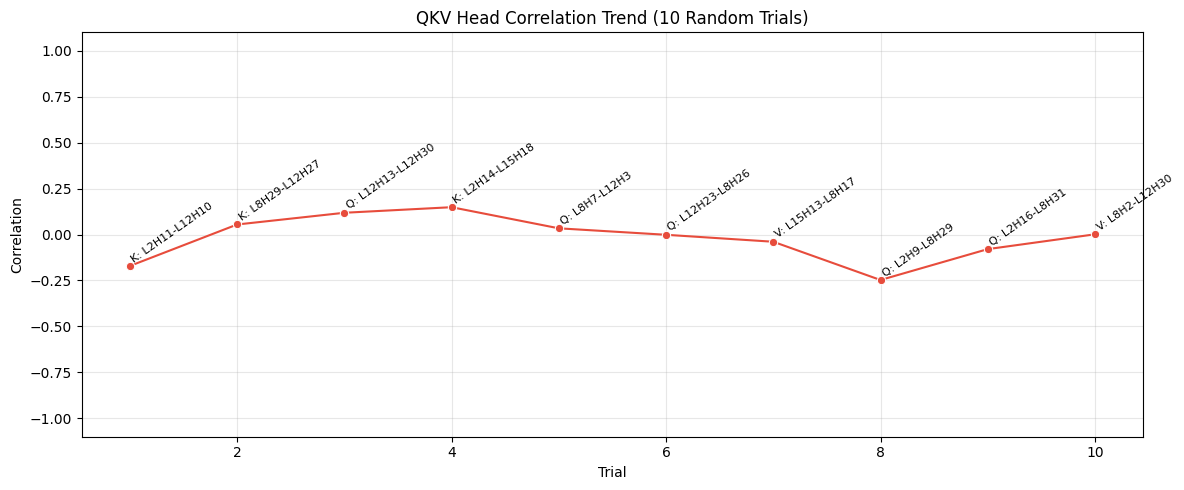


--- Correlation Results ---
   Trial             Label  Correlation
0      1   K: L2H11-L12H10    -0.170898
1      2   K: L8H29-L12H27     0.054565
2      3  Q: L12H13-L12H30     0.118347
3      4   K: L2H14-L15H18     0.148682
4      5     Q: L8H7-L12H3     0.033783
5      6   Q: L12H23-L8H26    -0.001412
6      7   V: L15H13-L8H17    -0.039307
7      8     Q: L2H9-L8H29    -0.247437
8      9    Q: L2H16-L8H31    -0.079407
9     10    V: L8H2-L12H30     0.001162


/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


In [10]:
import torch
import time
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import pearsonr
from transformers import AutoModelForCausalLM, AutoTokenizer

# --- CONFIGURATION (Assumed from your existing setup) ---
# TARGET_LAYERS = [2, 8, 12, 15]
# MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"
# DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# OUT_DIR = Path("qkv_outputs")
# OUT_DIR.mkdir(exist_ok=True)

# 1. Load Model and Tokenizer ONCE (Your provided snippet)
dtype = torch.bfloat16 if DEVICE == "cuda" else torch.float32

print(f"Loading model: {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN,
    torch_dtype=dtype,
    device_map="auto" if DEVICE == "cuda" else None,
)

if DEVICE != "cuda":
    model.to(DEVICE)
model.eval()

# 2. Optimized Extraction Function
def run_hf_layer_extraction(prompts, model, tokenizer, layer_idx):
    """Extracts QKV for a specific layer using the already loaded model."""
    attn = model.model.layers[layer_idx].self_attn
    num_heads = int(model.config.num_attention_heads)
    num_kv_heads = int(getattr(model.config, "num_key_value_heads", num_heads))
    head_dim = int(getattr(model.config, "head_dim", model.config.hidden_size // num_heads))
    hidden_size = num_heads * head_dim

    def expand_kv_to_q_heads(x):
        b, t, _ = x.shape
        x = x.view(b, t, num_kv_heads, head_dim)
        if num_kv_heads != num_heads:
            repeat = num_heads // num_kv_heads
            x = x.repeat_interleave(repeat, dim=2)
        return x.reshape(b, t, hidden_size)

    cache = {}
    def mk_hook(name):
        def _hook(_module, _inp, out):
            cache[name] = out.detach()
        return _hook

    handles = [
        attn.q_proj.register_forward_hook(mk_hook("q")),
        attn.k_proj.register_forward_hook(mk_hook("k")),
        attn.v_proj.register_forward_hook(mk_hook("v")),
    ]

    q_store = torch.zeros((NUM_SAMPLES, MAX_INPUT_TOKENS, hidden_size), dtype=STORE_DTYPE)
    k_store = torch.zeros_like(q_store)
    v_store = torch.zeros_like(q_store)
    lengths, latencies = [], []
    model_device = next(model.parameters()).device

    # Warmup for this specific layer/hook
    warm = tokenizer(prompts[0], return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model_device)
    with torch.inference_mode():
        _ = model(**warm, use_cache=False)

    print(f"Processing Layer {layer_idx}...")
    for i, p in enumerate(prompts):
        cache.clear()
        inputs = tokenizer(p, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model_device)

        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            _ = model(**inputs, use_cache=False)
        if DEVICE == "cuda": torch.cuda.synchronize()
        latencies.append(time.perf_counter() - t0)

        q = cache["q"][0].to(STORE_DTYPE).cpu()
        k = expand_kv_to_q_heads(cache["k"])[0].to(STORE_DTYPE).cpu()
        v = expand_kv_to_q_heads(cache["v"])[0].to(STORE_DTYPE).cpu()

        L = min(q.shape[0], k.shape[0], v.shape[0], MAX_INPUT_TOKENS)
        lengths.append(int(L))
        q_store[i, :L] = q[:L]
        k_store[i, :L] = k[:L]
        v_store[i, :L] = v[:L]

    for h in handles: h.remove()

    out_file = OUT_DIR / f"hf_qkv_layer{layer_idx}.pt"
    torch.save({"layer_idx": layer_idx, "q": q_store, "k": k_store, "v": v_store}, out_file)
    return str(out_file)

# 3. Main Loop: Run Extraction across target layers
target_layers = [2, 8, 12, 15]
layer_files = {lyr: run_hf_layer_extraction(prompts, model, tokenizer, lyr) for lyr in target_layers}

# 4. Correlation Analysis & Plotting
def get_head_vector(file_path, head_idx, tensor_type='q'):
    data = torch.load(file_path, map_location='cpu')
    # Reshape from [Samples, Tokens, 2048] to [Samples, Tokens, 32, 64]
    tensor = data[tensor_type].view(NUM_SAMPLES, MAX_INPUT_TOKENS, 32, 64)
    return tensor[:, :, head_idx, :].flatten().numpy()

results = []
print("\nRunning 10 correlation trials...")
for i in range(10):
    l1, l2 = random.choice(target_layers), random.choice(target_layers)
    h1, h2 = random.randint(0, 31), random.randint(0, 31)
    t_type = random.choice(['q', 'k', 'v'])

    vec1 = get_head_vector(layer_files[l1], h1, t_type)
    vec2 = get_head_vector(layer_files[l2], h2, t_type)

    corr, _ = pearsonr(vec1, vec2)
    results.append({"Trial": i + 1, "Label": f"{t_type.upper()}: L{l1}H{h1}-L{l2}H{h2}", "Correlation": corr})

df_corr = pd.DataFrame(results)

# 5. Visualizing the Trend
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_corr, x="Trial", y="Correlation", marker='o', color='#e74c3c')
for i, row in df_corr.iterrows():
    plt.text(row['Trial'], row['Correlation'] + 0.02, row['Label'], fontsize=8, rotation=35)

plt.ylim(-1.1, 1.1)
plt.title("QKV Head Correlation Trend (10 Random Trials)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n--- Correlation Results ---")
print(df_corr)

Running 10 experiments...


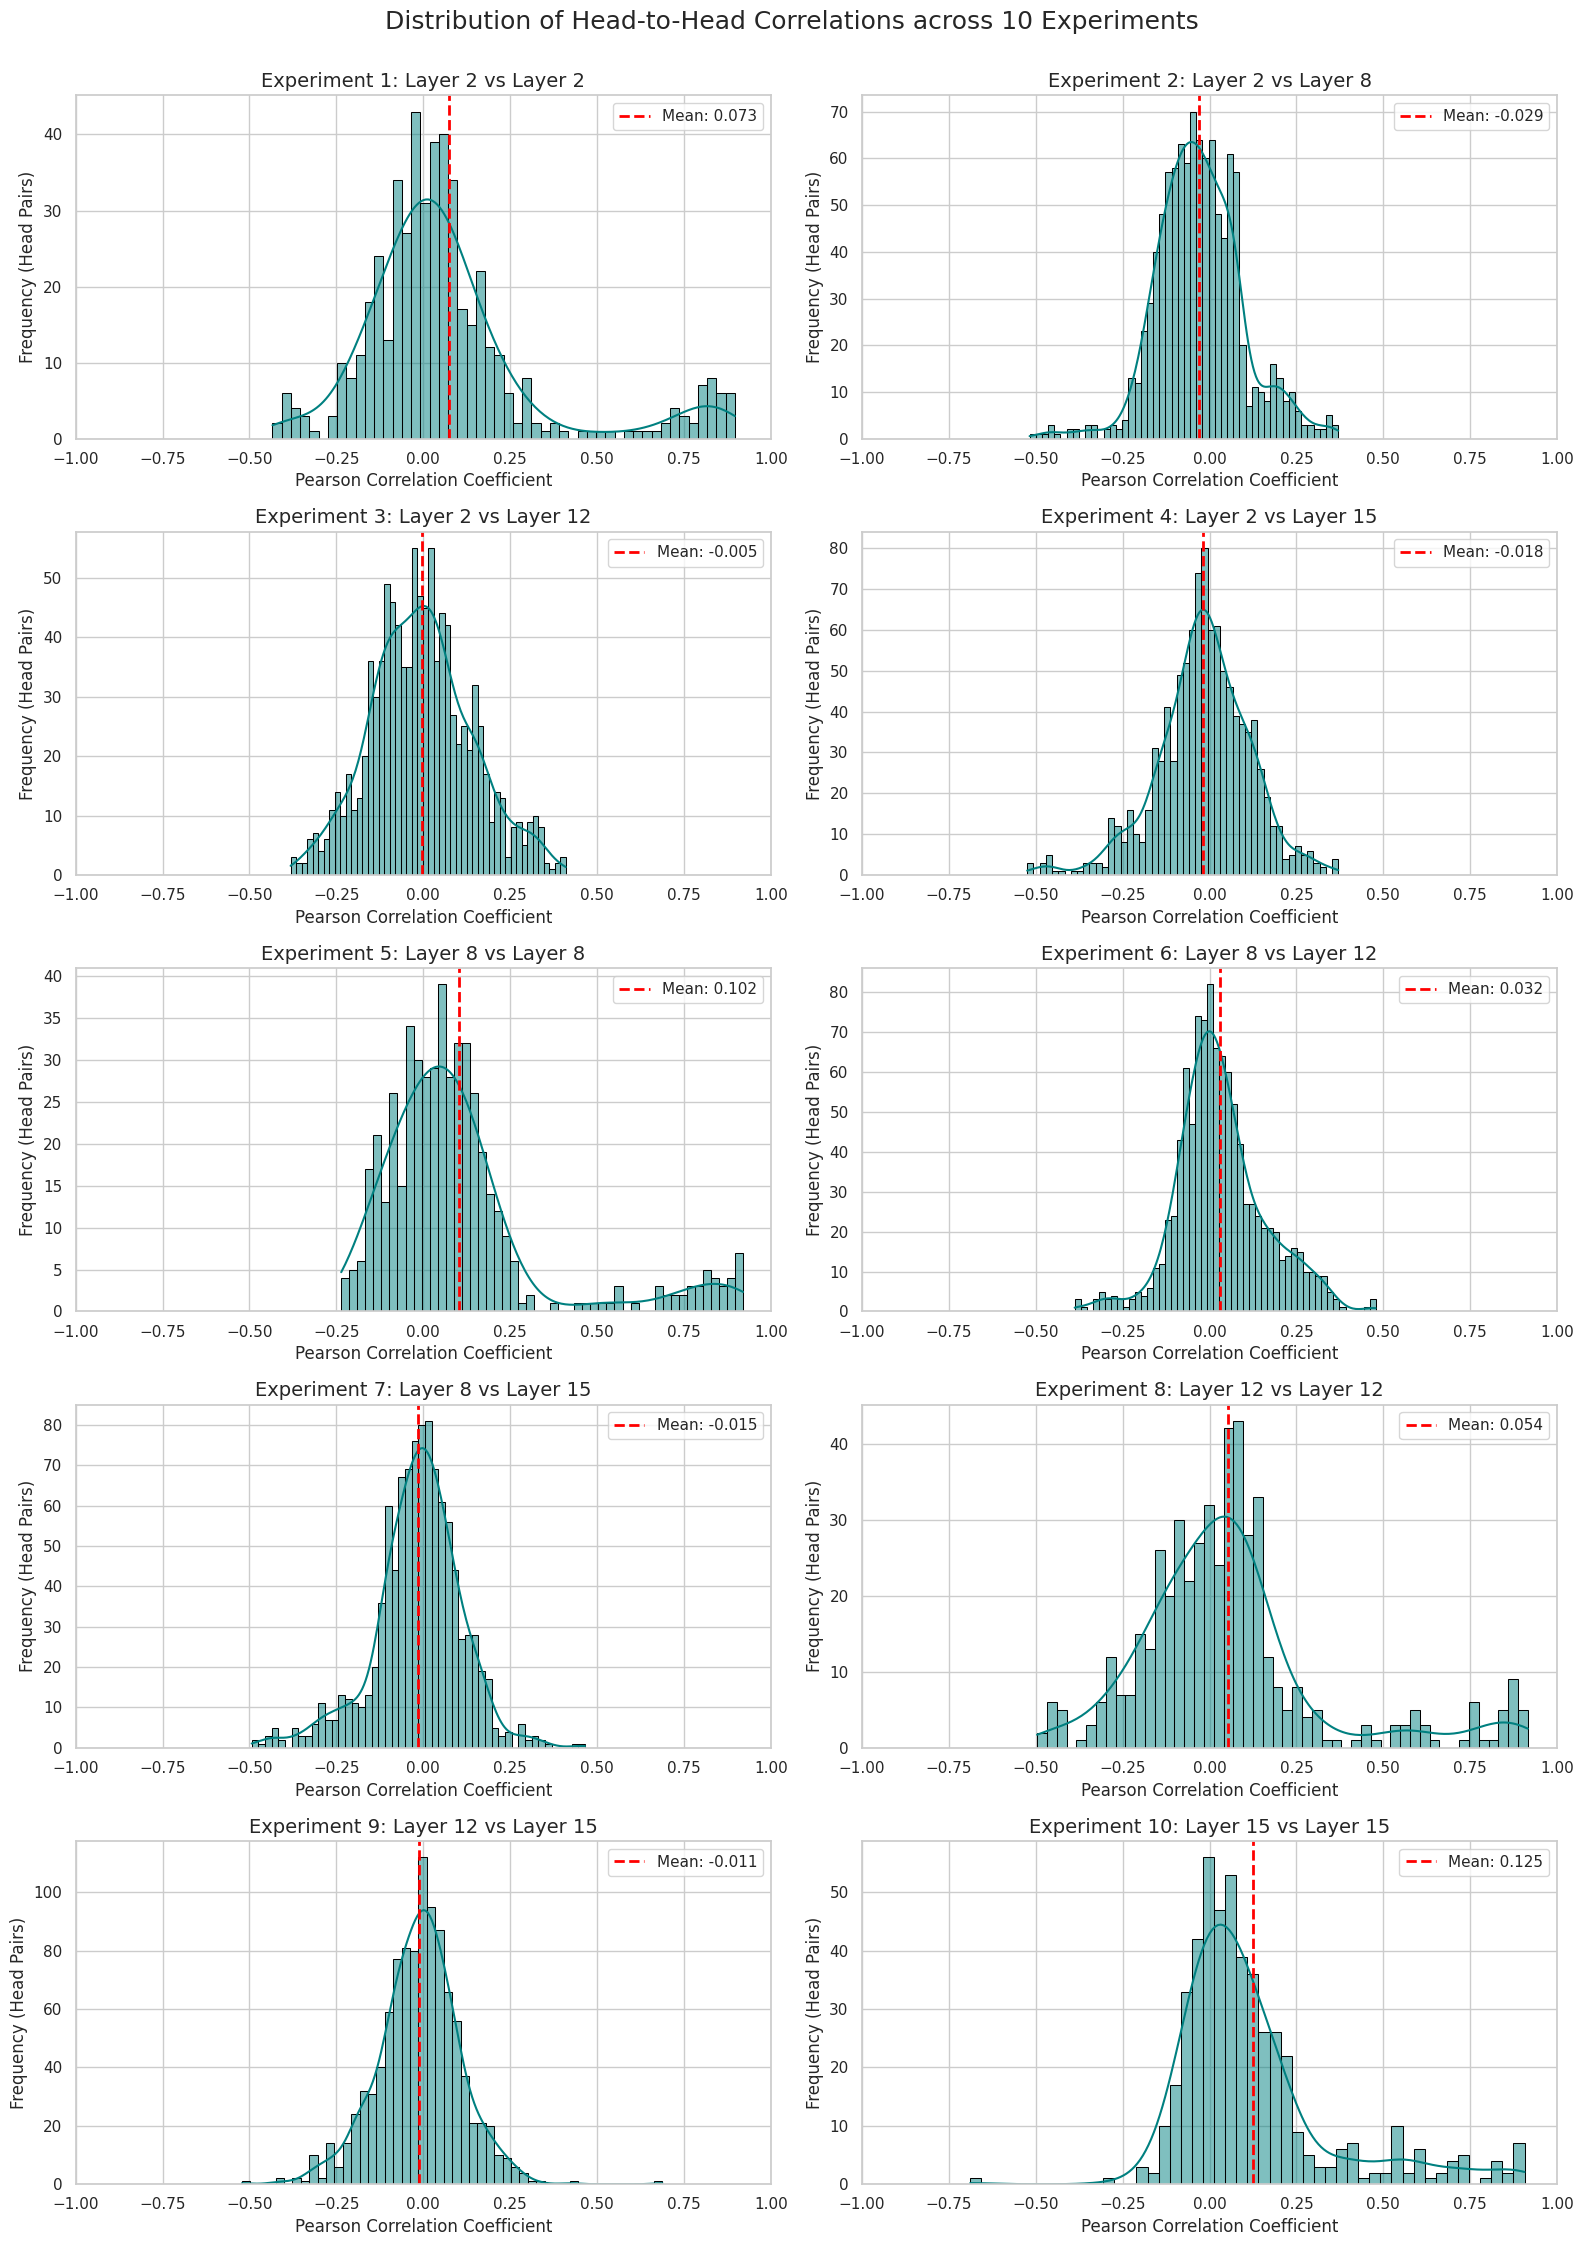

In [11]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# --- 1. CONFIGURATION (Matching your previous runs) ---
# TARGET_LAYERS = [2, 8, 12, 15]
# These 4 layers produce exactly 10 unique combinations (4 choose 2 + 4 self)
experiments = list(itertools.combinations_with_replacement(TARGET_LAYERS, 2))

# --- 2. OPTIMIZED CORRELATION FUNCTION ---
def get_all_correlations(file_a, file_b):
    """Computes all 1,024 head-to-head correlations between two layers."""
    # Load and reshape to (32 heads, Flat_Features)
    # Using 'q' as the example tensor from your previous extraction
    data_a = torch.load(file_a)['q'].view(NUM_SAMPLES, MAX_INPUT_TOKENS, 32, 64)
    data_b = torch.load(file_b)['q'].view(NUM_SAMPLES, MAX_INPUT_TOKENS, 32, 64)

    # Permute to (Heads, Samples*Tokens*Dim) and flatten features
    vecs_a = data_a.permute(2, 0, 1, 3).reshape(32, -1).to(torch.float32)
    vecs_b = data_b.permute(2, 0, 1, 3).reshape(32, -1).to(torch.float32)

    # Pearson Correlation via Matrix Multiplication (Normalized Dot Product)
    vecs_a -= vecs_a.mean(dim=1, keepdim=True)
    vecs_b -= vecs_b.mean(dim=1, keepdim=True)

    # Avoid division by zero
    norm_a = vecs_a.norm(dim=1, keepdim=True)
    norm_b = vecs_b.norm(dim=1, keepdim=True)
    vecs_a /= (norm_a + 1e-8)
    vecs_b /= (norm_b + 1e-8)

    corr_matrix = torch.mm(vecs_a, vecs_b.t())

    if file_a == file_b:
        # For self-comparison, ignore the diagonal (self-correlation of 1.0)
        return corr_matrix[torch.triu(torch.ones(32, 32), diagonal=1).bool()].cpu().numpy()

    return corr_matrix.flatten().cpu().numpy()

# --- 3. GENERATE PLOTS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(5, 2, figsize=(16, 22))
axes = axes.flatten()

print(f"Running {len(experiments)} experiments...")

for i, (l1, l2) in enumerate(experiments):
    f1, f2 = layer_files[l1], layer_files[l2]
    corrs = get_all_correlations(f1, f2)

    # Calculate the average score for this experiment
    avg_score = np.mean(corrs)

    # Plotting
    sns.histplot(corrs, bins=50, kde=True, ax=axes[i], color='teal', edgecolor='black')
    axes[i].axvline(avg_score, color='red', linestyle='--', linewidth=2, label=f'Mean: {avg_score:.3f}')

    axes[i].set_title(f"Experiment {i+1}: Layer {l1} vs Layer {l2}", fontsize=14)
    axes[i].set_xlim(-1, 1) # Correlation range
    axes[i].set_xlabel("Pearson Correlation Coefficient")
    axes[i].set_ylabel("Frequency (Head Pairs)")
    axes[i].legend()

plt.tight_layout()
plt.suptitle("Distribution of Head-to-Head Correlations across 10 Experiments", fontsize=18, y=1.02)
plt.show()

IndexError: index 10 is out of bounds for axis 0 with size 10

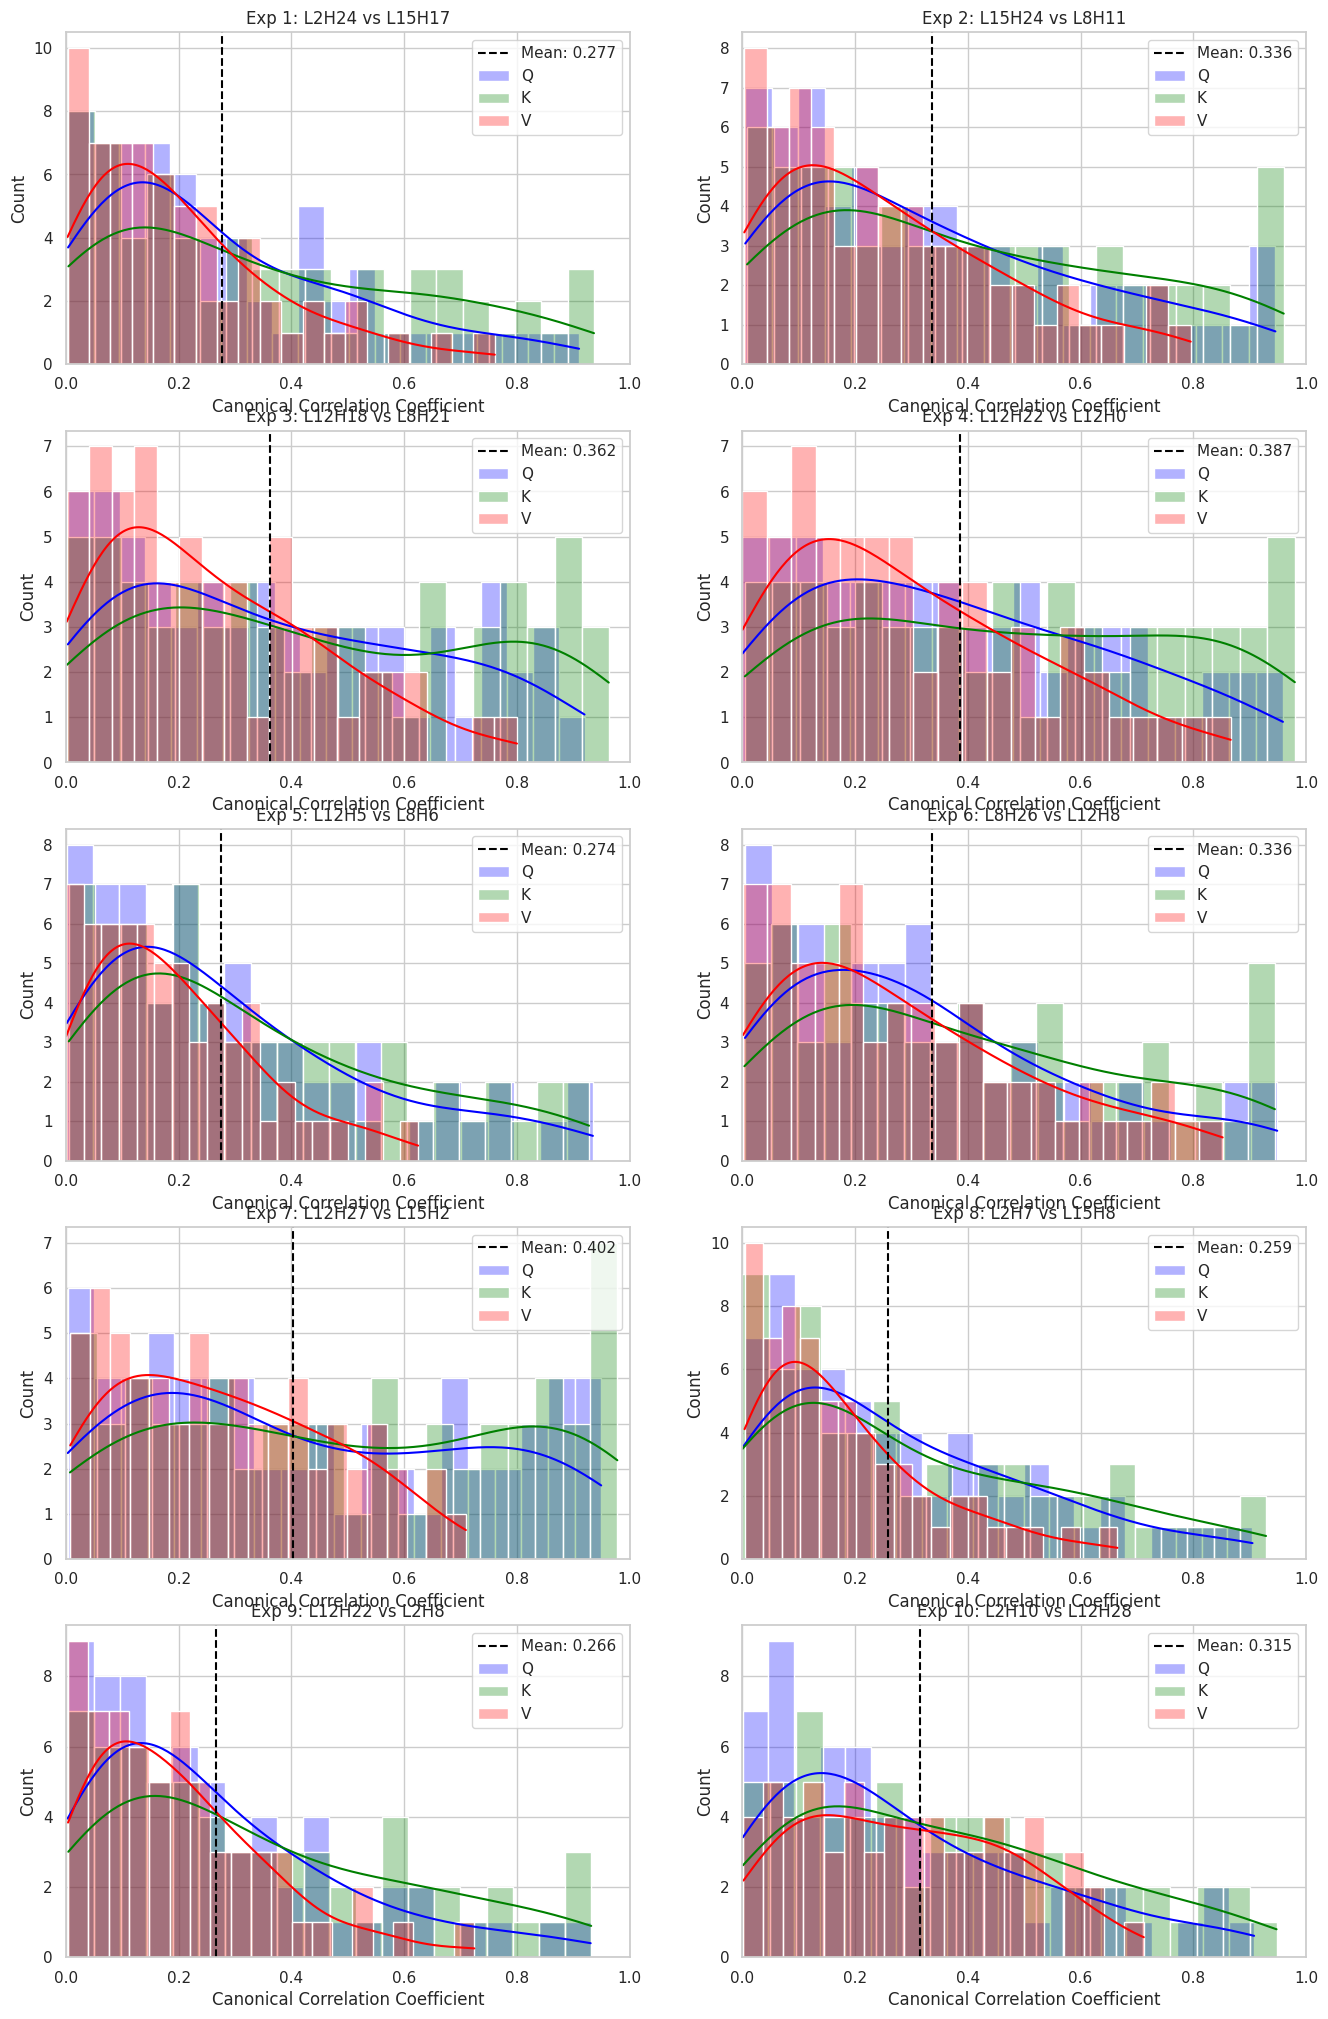

In [14]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_head_matrix(layer_idx, head_idx, tensor_type='q'):
    """Extracts activations for a specific head as a [N_tokens, Head_Dim] matrix."""
    path = layer_files[layer_idx]
    data = torch.load(path, map_location='cpu')
    # Reshape from [100, 128, 2048] to [100, 128, 32, 64]
    tensor = data[tensor_type].view(NUM_SAMPLES, MAX_INPUT_TOKENS, 32, 64)
    # Return flattened tokens: [12800, 64]
    return tensor.reshape(-1, 32, 64)[:, head_idx, :].to(torch.float32)

def compute_pca_corrs(act1, act2):
    """Computes Canonical Correlation coefficients (Subspace Similarity) via SVD."""
    # 1. Center the data
    act1 = act1 - act1.mean(dim=0)
    act2 = act2 - act2.mean(dim=0)

    # 2. Get Orthogonal Bases (PCA) using SVD
    # The U matrix from SVD provides an orthonormal basis for the activations
    u1, _, _ = torch.linalg.svd(act1, full_matrices=False)
    u2, _, _ = torch.linalg.svd(act2, full_matrices=False)

    # 3. Compute Singular Values of the projection matrix (Canonical Correlations)
    # This represents how well the dimensions of the two head-subspaces align.
    with torch.no_grad():
        m = torch.matmul(u1.t(), u2)
        corrs = torch.linalg.svdvals(m)

    return corrs.cpu().numpy()

# 1. Define 10 Experiments (Random Head Pairs from your TARGET_LAYERS)
num_experiments = 100
experiments = []
for _ in range(num_experiments):
    l1, l2 = random.choice(target_layers), random.choice(target_layers)
    h1, h2 = random.randint(0, 31), random.randint(0, 31)
    experiments.append((l1, h1, l2, h2))

# 2. Plotting (10 Histograms, each showing Q, K, and V distributions)
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for i, (l1, h1, l2, h2) in enumerate(experiments):
    ax = axes[i]
    # Calculate for each type
    q_corrs = compute_pca_corrs(get_head_matrix(l1, h1, 'q'), get_head_matrix(l2, h2, 'q'))
    k_corrs = compute_pca_corrs(get_head_matrix(l1, h1, 'k'), get_head_matrix(l2, h2, 'k'))
    v_corrs = compute_pca_corrs(get_head_matrix(l1, h1, 'v'), get_head_matrix(l2, h2, 'v'))

    # Overlay histograms for Q, K, V
    sns.histplot(q_corrs, bins=20, kde=True, ax=ax, color='blue', label='Q', alpha=0.3)
    sns.histplot(k_corrs, bins=20, kde=True, ax=ax, color='green', label='K', alpha=0.3)
    sns.histplot(v_corrs, bins=20, kde=True, ax=ax, color='red', label='V', alpha=0.3)

    # Calculate and display the combined average
    avg_score = np.mean([q_corrs, k_corrs, v_corrs])
    ax.axvline(avg_score, color='black', linestyle='--', label=f'Mean: {avg_score:.3f}')

    ax.set_title(f"Exp {i+1}: L{l1}H{h1} vs L{l2}H{h2}")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Canonical Correlation Coefficient")
    ax.legend()

plt.tight_layout()
plt.suptitle("Subspace Alignment (PCA-Correlation) for 10 Random Head Pairs", fontsize=20, y=1.01)
plt.show()

Extracting Layer 2
Extracting Layer 8
Extracting Layer 12
Extracting Layer 15


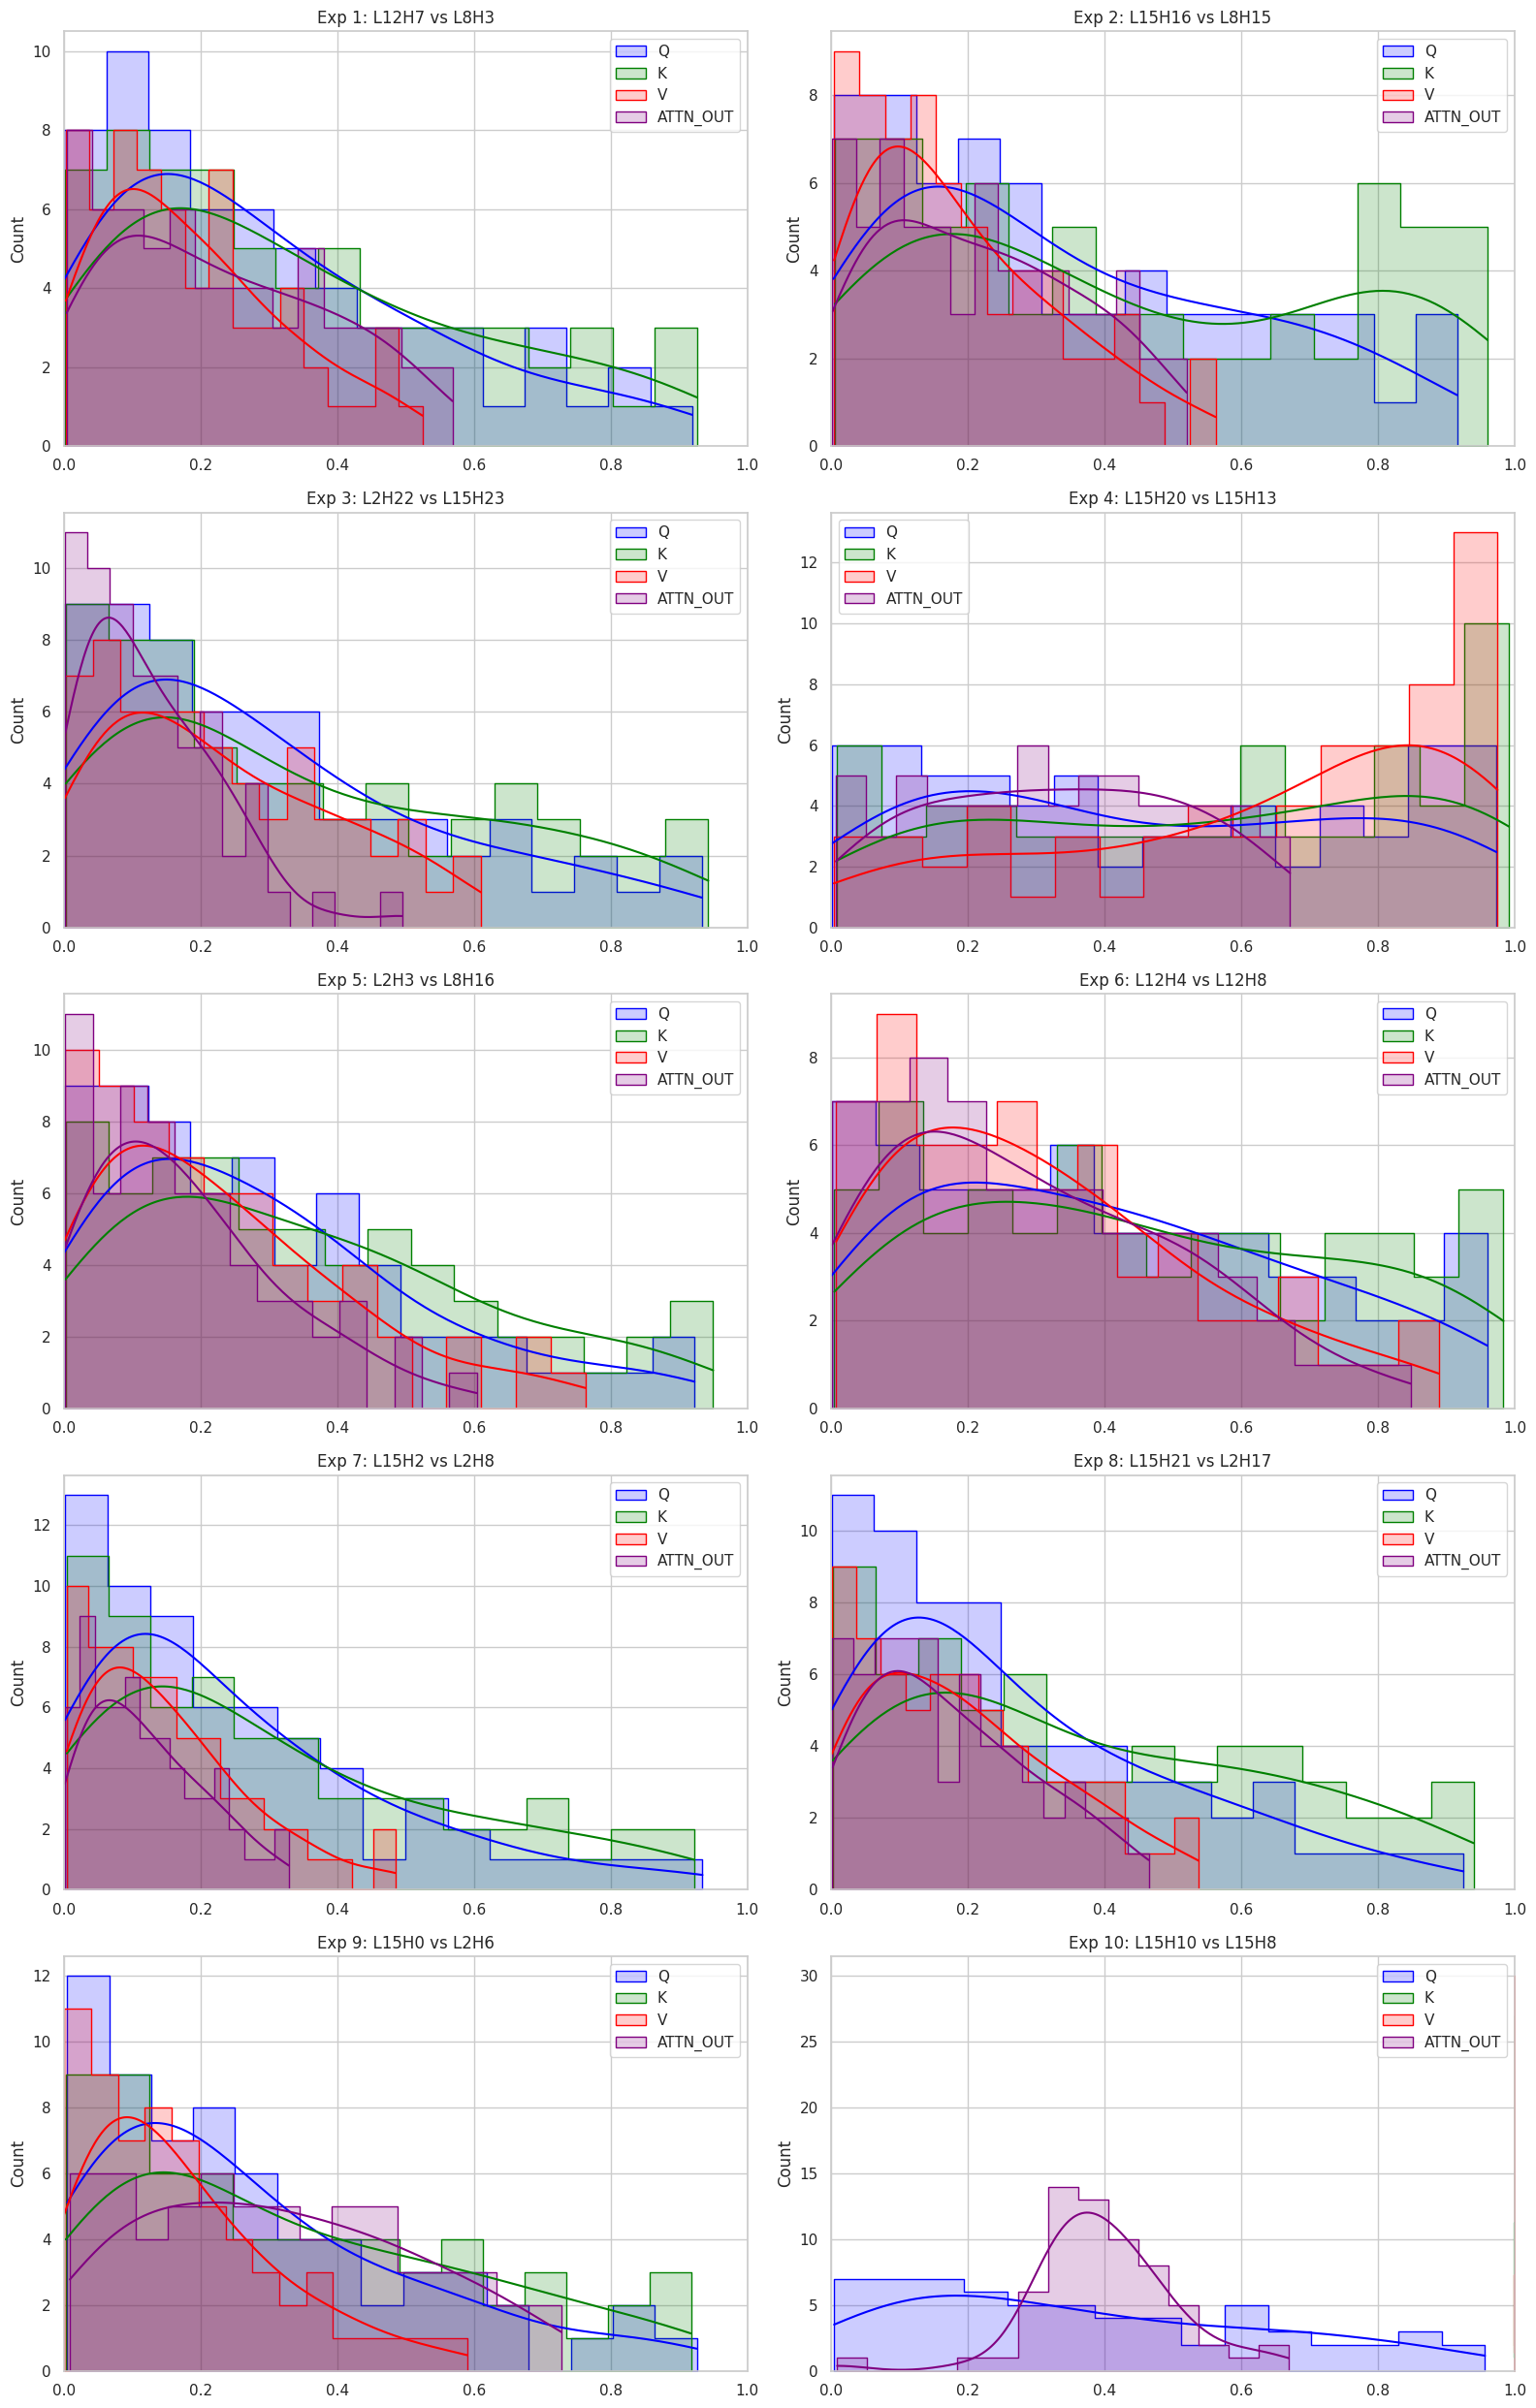

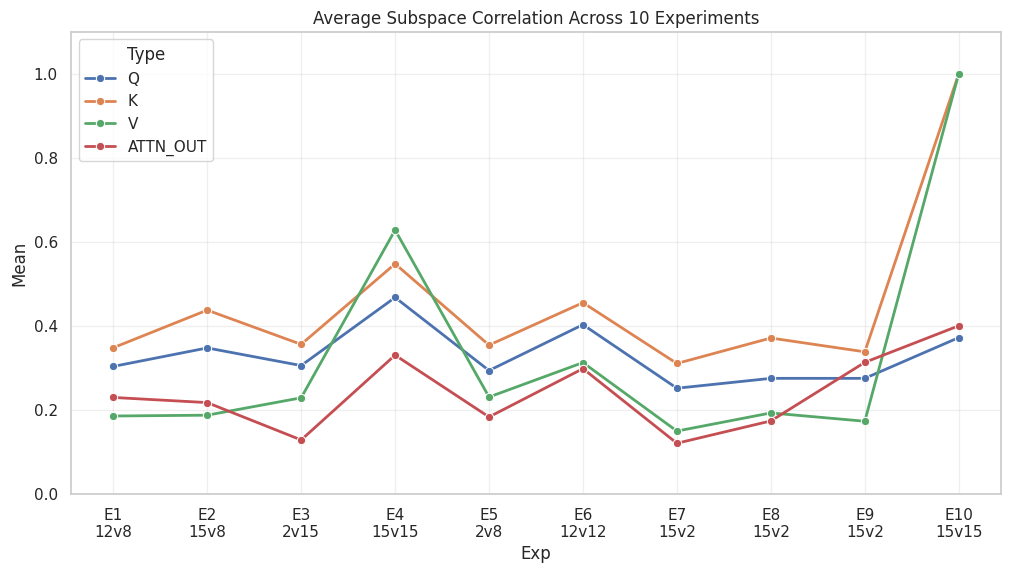

In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import random

# --- 1. FIXED EXTRACTION (Handles GQA Expansion) ---
def run_hf_with_attn_fixed(prompts, model, tokenizer, layer_idx):
    attn = model.model.layers[layer_idx].self_attn
    num_heads = model.config.num_attention_heads
    num_kv_heads = getattr(model.config, "num_key_value_heads", num_heads)
    head_dim = model.config.hidden_size // num_heads
    hidden_size = model.config.hidden_size

    cache = {}
    def mk_hook(name, is_input=False):
        def _hook(_m, _i, _o): cache[name] = (_i[0] if is_input else _o).detach()
        return _hook

    handles = [
        attn.q_proj.register_forward_hook(mk_hook("q")),
        attn.k_proj.register_forward_hook(mk_hook("k")),
        attn.v_proj.register_forward_hook(mk_hook("v")),
        attn.o_proj.register_forward_hook(mk_hook("attn_out", is_input=True))
    ]

    storage = {k: torch.zeros((NUM_SAMPLES, MAX_INPUT_TOKENS, hidden_size), dtype=STORE_DTYPE)
               for k in ['q', 'k', 'v', 'attn_out']}

    def expand_kv(x):
        """Repeats KV heads to match the number of Q heads."""
        if num_kv_heads == num_heads: return x
        b, t, _ = x.shape
        x = x.view(b, t, num_kv_heads, head_dim)
        x = x.repeat_interleave(num_heads // num_kv_heads, dim=2)
        return x.reshape(b, t, hidden_size)

    print(f"Extracting Layer {layer_idx}")
    for i, p in enumerate(prompts):
        inputs = tokenizer(p, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(model.device)
        with torch.inference_mode():
            _ = model(**inputs, use_cache=False)

        for k in ['q', 'k', 'v', 'attn_out']:
            val = cache[k]
            if k in ['k', 'v']: val = expand_kv(val)

            val = val[0].to(STORE_DTYPE).cpu()
            L = min(val.shape[0], MAX_INPUT_TOKENS)
            storage[k][i, :L] = val[:L]

    for h in handles: h.remove()
    out_file = OUT_DIR / f"layer_{layer_idx}_full.pt"
    torch.save(storage, out_file)
    return out_file

# Re-run extraction with the fix
layer_files = {lyr: run_hf_with_attn_fixed(prompts, model, tokenizer, lyr) for lyr in target_layers}

# --- 2. PCA CORRELATION & PLOTTING ---
all_stats = []
experiments = []
for _ in range(10):
    l1, l2 = random.choice(target_layers), random.choice(target_layers)
    h1, h2 = random.randint(0, 31), random.randint(0, 31)
    experiments.append((l1, h1, l2, h2))

fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for i, (l1, h1, l2, h2) in enumerate(experiments):
    ax = axes[i]
    colors = {'q': 'blue', 'k': 'green', 'v': 'red', 'attn_out': 'purple'}

    for t_type, color in colors.items():
        m1 = get_head_matrix_v2(layer_files[l1], h1, t_type)
        m2 = get_head_matrix_v2(layer_files[l2], h2, t_type)
        corrs = compute_pca_corrs(m1, m2)

        sns.histplot(corrs, bins=15, kde=True, ax=ax, color=color, label=t_type.upper(), alpha=0.2, element="step")
        all_stats.append({"Exp": i+1, "Type": t_type.upper(), "Mean": np.mean(corrs), "Label": f"L{l1}H{h1}-L{l2}H{h2}"})

    ax.set_title(f"Exp {i+1}: L{l1}H{h1} vs L{l2}H{h2}")
    ax.set_xlim(0, 1); ax.legend()

plt.tight_layout()
plt.show()

# # --- 3. COMBINED LINE PLOT ---
# df_stats = pd.DataFrame(all_stats)
# plt.figure(figsize=(12, 6))
# sns.lineplot(data=df_stats, x="Exp", y="Mean", hue="Type", marker='o', linewidth=2)
# plt.xticks(range(1, 11), [f"E{i+1}\n{experiments[i][0]}v{experiments[i][2]}" for i in range(10)])
# plt.title("Average Subspace Correlation Across 10 Experiments")
# plt.grid(True, alpha=0.3); plt.ylim(0, 1.1)
# plt.show()